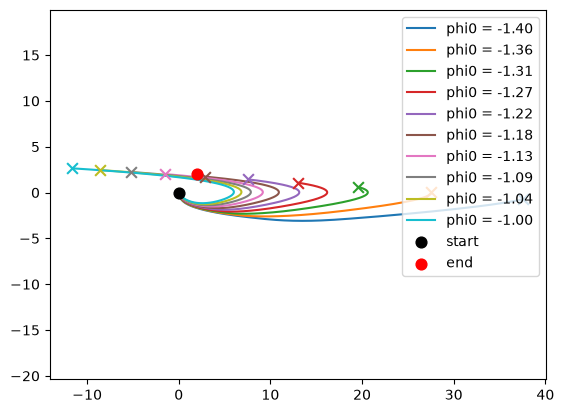

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k = 1
A,B = 2,2

def phi_of_t(t, phi0):
    return np.arctan(t**2 / 2 + np.tan(phi0))

def rhs(t, z, phi0):
    x, y = z
    p = phi_of_t(t, phi0)
    return [-t * y + k * np.cos(p), k * np.sin(p)]

phi0_values = np.linspace(-1.4, -1.0, 10)
Tmax = 6.0
t = np.linspace(0, Tmax, 200)
start = (0, 0)

for phi0 in phi0_values:
    res = solve_ivp(rhs, (0, Tmax), start, t_eval=t, args=(phi0,))
    x, y = res.y
    line, = plt.plot(x, y, label=f"phi0 = {phi0:.2f}")
    plt.scatter(x[-1], y[-1], color=line.get_color(), marker="x", s=60, zorder=3)

plt.scatter(*start, color="black", marker="o", s=60, zorder=3, label="start")
plt.scatter(*(A,B), color="red", marker="o", s=60, zorder=3, label="end")

plt.axis("equal")
plt.legend()
plt.show()